In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv("Dataset .csv")
print(df.shape)
df.head()

(9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [4]:
# "Aggregate rating" = 0 means "Not rated", not a real score — remove these
before = len(df)
df = df[df["Rating text"].str.lower() != "not rated"].copy()
print(f"Dropped {before - len(df)} unrated restaurants -> {len(df)} remain")

# Fill missing cuisines
df["Cuisines"] = df["Cuisines"].fillna("Unknown")

Dropped 2148 unrated restaurants -> 7403 remain


In [6]:
from sklearn.preprocessing import LabelEncoder

# Number of cuisines per restaurant + primary cuisine
df["Cuisine Count"] = df["Cuisines"].apply(lambda x: len(x.split(",")))
df["Primary Cuisine"] = df["Cuisines"].apply(lambda x: x.split(",")[0].strip())

# Keep top 20 cuisines, group rest as "Other"
top_cuisines = df["Primary Cuisine"].value_counts().nlargest(20).index
df["Primary Cuisine"] = df["Primary Cuisine"].where(df["Primary Cuisine"].isin(top_cuisines), "Other")

# Encode Yes/No columns
for col in ["Has Table booking", "Has Online delivery"]:
    df[col] = df[col].map({"Yes": 1, "No": 0})

# Encode categories to numbers
le_city = LabelEncoder()
df["City Encoded"] = le_city.fit_transform(df["City"])

le_cuisine = LabelEncoder()
df["Primary Cuisine Encoded"] = le_cuisine.fit_transform(df["Primary Cuisine"])

df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes,Cuisine Count,Primary Cuisine,City Encoded,Primary Cuisine Encoded
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,No,3,4.8,Dark Green,Excellent,314,3,Other,73,16
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,No,3,4.5,Dark Green,Excellent,591,1,Japanese,73,12
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,No,4,4.4,Green,Very Good,270,4,Other,75,16
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,No,4,4.9,Dark Green,Excellent,365,2,Japanese,75,12
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,No,4,4.8,Dark Green,Excellent,229,2,Japanese,75,12


In [7]:
from sklearn.model_selection import train_test_split

features = ["Average Cost for two", "Price range", "Votes",
            "Has Table booking", "Has Online delivery",
            "Cuisine Count", "City Encoded", "Primary Cuisine Encoded"]
target = "Aggregate rating"

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (5922, 8), Test: (1481, 8)


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42, max_depth=8),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, max_depth=12),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    print(f"{name:20s} | RMSE: {rmse:.4f} | R2: {r2:.4f}")

Linear Regression    | RMSE: 0.4677 | R2: 0.2927
Decision Tree        | RMSE: 0.3741 | R2: 0.5475
Random Forest        | RMSE: 0.3391 | R2: 0.6282


Votes                      0.616155
City Encoded               0.114452
Average Cost for two       0.109996
Primary Cuisine Encoded    0.076401
Price range                0.028766
Cuisine Count              0.028430
Has Online delivery        0.017013
Has Table booking          0.008788
dtype: float64


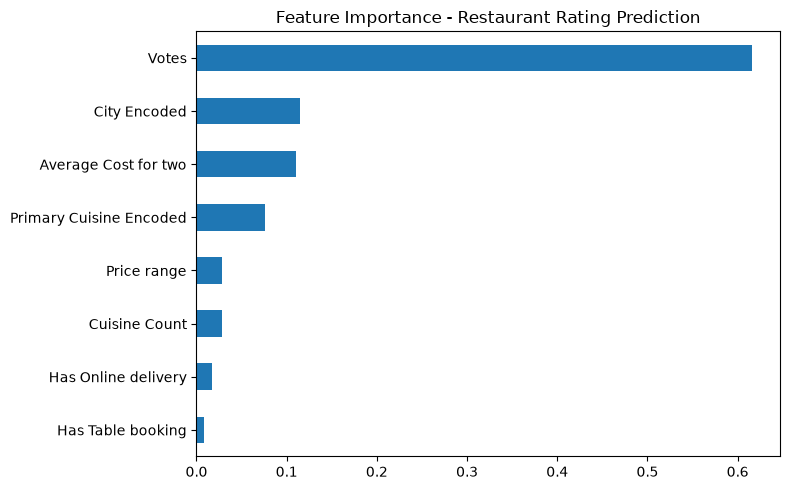

In [9]:
import matplotlib.pyplot as plt

rf = models["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
print(importances)

importances.plot(kind="barh", figsize=(8,5))
plt.gca().invert_yaxis()
plt.title("Feature Importance - Restaurant Rating Prediction")
plt.tight_layout()
plt.show()